#### 인공 신경망
- nn모듈 : 신경망을 구축하고 학습시키는데 필요한 모든 구성요소를 제공하는 핵심 모듈
- 주요 역할 및 구성요소
    1. 인공 신경망 레이어(Layer) : 입력데이터를 변환하는 다양한 층을 제공
        - 선형 레이어(nn.Linear) : 완전연결층
        - 합성곱 레이어(nn.Conv2d) : 이미지 처리에 쓰이는 CNN레이어
        - 순환 레이어(nn.LSTM, nn.GRU) : 텍스트, 시계열 처리에 쓰이는 RNN 레이어
    2. 활성화 함수(Activation Functions) : 비선형성을 추가하여 모델이 복잡한 패턴을 학습할 수 있도록 해줌
        - nn.ReLU(), nn.Sigmoid(), nn.Softmax()...
    3. 손실함수(Loss Functions) : 모델의 예측값과 실제 값의 오차를 계산
        - nn.MSELoss(), nn.CrossEntropyLoss() 등
    4. 컨테이너 : 여러 레이어를 묶어서 하나의 모델로 구조화
        - nn.Module : 모든 신경망 모델의 기본 클래스
        - 자신이 만드는 모든 커스텀 모델은 nn.Module을 상속받아 정의하여 사용
        - nn.Sequential : 레이어를 순차적으로 연결해주는 간단한 래퍼임.

In [1]:
import torch
from torch import nn
from torchviz import make_dot

Linear(in_features=1, out_features=1, bias=True)
w = Parameter containing:
tensor([[-0.1655]], requires_grad=True)
b = Parameter containing:
tensor([0.9952], requires_grad=True)
tensor([0.8298], grad_fn=<UnsafeViewBackward0>)
tensor([0.8298], grad_fn=<AddBackward0>)


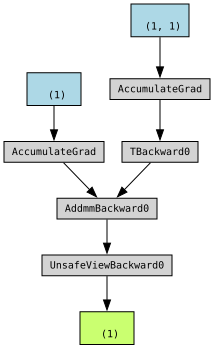

In [ ]:
x = torch.tensor([1.])

model = nn.Linear(1,1) #nn.Linear(입력값, 출력값) <- 개수 넣는 거임
print(model)

print('w =', model.weight)
print('b =', model.bias)

y = model(x)
print(y)

# y = x@weight + bias
y2 = x@model.weight + model.bias
print(y2)

make_dot(y)

fc1의 w = Parameter containing:
tensor([[ 0.0600],
        [-0.0082],
        [-0.1222]], requires_grad=True)
fc1의 가중치 행렬 = torch.Size([3, 1])
fc1의 b = Parameter containing:
tensor([-0.7156, -0.8732, -0.7899], requires_grad=True)
fc1의 편향 = torch.Size([3])
------------------------------
fc2의 w = Parameter containing:
tensor([[0.0803, 0.0067, 0.5605]], requires_grad=True)
fc2의 b = Parameter containing:
tensor([-0.3206], requires_grad=True)
------------------------------
tensor([-0.6556, -0.8814, -0.9121], grad_fn=<UnsafeViewBackward0>)
tensor([-0.8904], grad_fn=<UnsafeViewBackward0>)
tensor([-0.8904], grad_fn=<AddBackward0>)


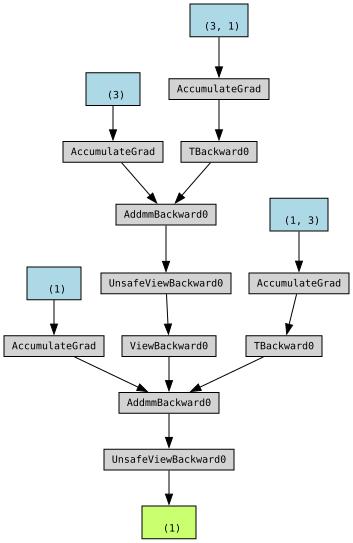

In [12]:
fc1 = nn.Linear(1,3)
fc2 = nn.Linear(3,1)

print('fc1의 w =', fc1.weight)
print('fc1의 가중치 행렬 =', fc1.weight.shape)
# w.shape = (out_features, in_features)

print('fc1의 b =', fc1.bias)
print('fc1의 편향 =', fc1.bias.shape)
print('-'*30)

print('fc2의 w =', fc2.weight)
print('fc2의 b =', fc2.bias)
print('-'*30)

x = torch.tensor([1.])

x = fc1(x)
print(x)

y = fc2(x)
print(y)

x = torch.tensor([1.])
y2 = x @ (fc1.weight.T + fc1.bias) @ fc2.weight.T + fc2.bias
print(y2)

make_dot(y)

Feature와 Channel의 차이
| 구분 | Feature | Channel |
| :--- | :--- | :--- |
| 의미 | 데이터가 가진 특성 혹은 변수 | 데이터의 독립적인 데이터 경로 또는 구성요소 |
| 예시 | 나이, 키, 몸무게 등 | RGB 이미지 R, G, B |
| 주로 사용하는 곳 | 일반적인 데이터, 머신러닝, 완전연결층 | 이미지 처리, CNN, 신호처리 |

tensor([-1.5036, -0.0398])
tensor([-1.3761,  0.1702, -0.7732], grad_fn=<UnsafeViewBackward0>)


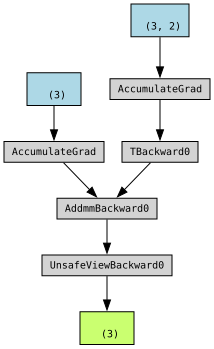

In [ ]:
model = nn.Linear(2,3)
# 2개의 채널(or feature)을 가진 데이터에 대해 3개의 채널을 가지는 데이터로 변환
x = torch.randn(2)
print(x)
print(model(x))

make_dot(model(x))

tensor([[-0.0912, -0.0060],
        [ 0.9489, -0.5722],
        [-3.2448,  0.1613],
        [ 1.1507,  0.9765],
        [-0.7326, -0.7260]])
tensor([[ 0.1174, -0.1239, -0.0911],
        [ 0.9621,  0.0324, -0.7124],
        [-1.3700,  0.1726,  0.8295],
        [-0.0234, -0.7618,  0.1980],
        [ 0.3374,  0.3112, -0.3726]], grad_fn=<AddmmBackward0>)
torch.Size([5, 3])
torch.Size([4, 5, 3])
torch.Size([2, 3, 6, 5, 3, 3])


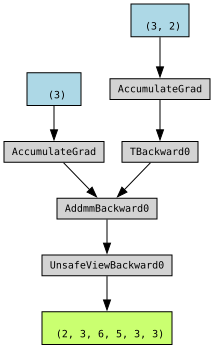

In [18]:
model = nn.Linear(2,3)
x = torch.randn(5, 2) # 2개의 특징을 가진 데이터 5개 생성 

print(x)
model_x = model(x)
print(model_x)
print(model_x.shape)

x = torch.randn(4,5,2)
print(model(x).shape)

x = torch.randn(2,3,6,5,3,2)
print(model(x).shape)

make_dot(model(x))

In [ ]:
fc1 = nn.Linear(1,3)
fc2 = nn.Linear(3,1)

x = torch.tensor([1.])
x = fc1(x)
y = fc2(x)

model = nn.Sequential(fc1, fc2) #fc1, fc2...를 한꺼번에 하나로 합침
x = torch.tensor([1.])
print(model(x))

tensor([0.6154], grad_fn=<UnsafeViewBackward0>)


In [21]:
model= nn.Sequential(nn.Linear(2,5),nn.Linear(5,10), nn.Linear(10,3))

x = torch.randn(5,2)
print(model(x))

tensor([[ 0.0363,  0.0912,  0.0205],
        [-0.0130,  0.1228,  0.0685],
        [-0.0081,  0.0477,  0.0521],
        [-0.0216,  0.0567,  0.0653],
        [ 0.0793, -0.0024, -0.0321]], grad_fn=<AddmmBackward0>)
